In [3]:
%matplotlib inline
 
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
 
matplotlib.rcParams['figure.dpi'] = 200

import numpy as np
from scipy.integrate import quad

from basic_units import cos, degrees, radians


# Sezione d'urto differenziale Compton
$$
\begin{align}
\frac{d\sigma_{Compton}}{d\Omega} = \frac{r_e^2}{2}(\frac{\omega^\prime}{\omega})^2(\frac{\omega^\prime}{\omega} + \frac{\omega}{\omega^\prime} - sin^2 \theta) & \tag{1.1}
\end{align}
$$

calcolata nell'ambito dell'elettrodinamica quanto-relativistica (QED), per un fotone non polarizzato.

Si indica con $\omega$ l'energia del fotone entrante, con $\omega^\prime$ l'energia del fotone uscente e con $\theta$ l'angolo di scattering.


Inoltre per $\omega^\prime$ vale
$$
\begin{align}
\omega^\prime = \frac{\omega}{1 + \frac{\omega}{m}(1-cos\theta)}& \tag{1.2}
\end{align}
$$

## Definisco le costanti fisiche
- $r_e$: Raggio classico dell'elettrone, $r_e\approx2,8179403267 * 10^{-15} \space m$.
- $m_e$: Massa dell'elettrone, $m_e\approx0.51099895000\space eV$.
- $\sigma_T$: Sezione d'urto Thomson, $\sigma_T\approx 6.6524587321 * 10^{-29} \space m^2$

In [5]:
# Costanti fisiche

r_e = 2.8179403267e-15  # Raggio classico dell'elettrone (m)
m_e = 0.51099895000  # Energia a riposo dell'elettrone (MeV)

sigma_t = 6.6524587321e-29 # Sezione d'urto Thomson (m^2)

In [1]:
def omega_ratio(omega, theta):
    return 1.0 / (1.0 + (omega / m_e) * (1.0 - np.cos(theta)))

def dsigma_dOmega(omega, theta):
    """
    Sezione d'urto differenziale di Klein-Nishina.
    """
    ratio = omega_ratio(omega, theta)
    return 0.5 * (r_e**2) * (ratio**2) * (ratio + (1.0/ratio) - np.sin(theta)**2)

def dsigma_dtheta(theta, omega):
    """
    Sezione d'urto differenziale rispetto a theta.
    """
    return 2 * np.pi * dsigma_dOmega(omega, theta)

def dsigma_dtheta_integranda(theta, omega):
    return np.sin(theta) * dsigma_dtheta(theta, omega)


## Grafico della sezione d'urto differenziale in funzione dell'angolo di scattering $\theta$

Considerando un sistema di coordinate sferiche, per l'angolo solido: $d\Omega = d\phi sin(\theta)d\theta$.

Integrando l'espressione $(1.1)$ sull'angolo azimutale $d\phi$ tra $0$ e $2\pi$ si può produrre un grafico della sezione d'urto differenziale $\frac{d\sigma_C}{d\theta}$ in funzione dell'angolo di scattering $\theta$, fissando diversi valori dell'energia del fotone incidente $\omega$ nel range $10keV \div 0.1 \space Gev$.

Si ha:
$$
\begin{align}
\frac{d\sigma_{Compton}}{d\theta} = 2\pi \frac{r_e^2}{2}(\frac{\omega^\prime}{\omega})^2(\frac{\omega^\prime}{\omega} + \frac{\omega}{\omega^\prime} - sin^2 \theta) & \tag{1.3}
\end{align}
$$

[0.0, 1.0471975511965976, 2.0943951023931953, 3.141592653589793]
[TaggedValue(0.0, BasicUnit(rad)), TaggedValue(1.0471975511965976, BasicUnit(rad)), TaggedValue(2.0943951023931953, BasicUnit(rad)), TaggedValue(3.141592653589793, BasicUnit(rad))]


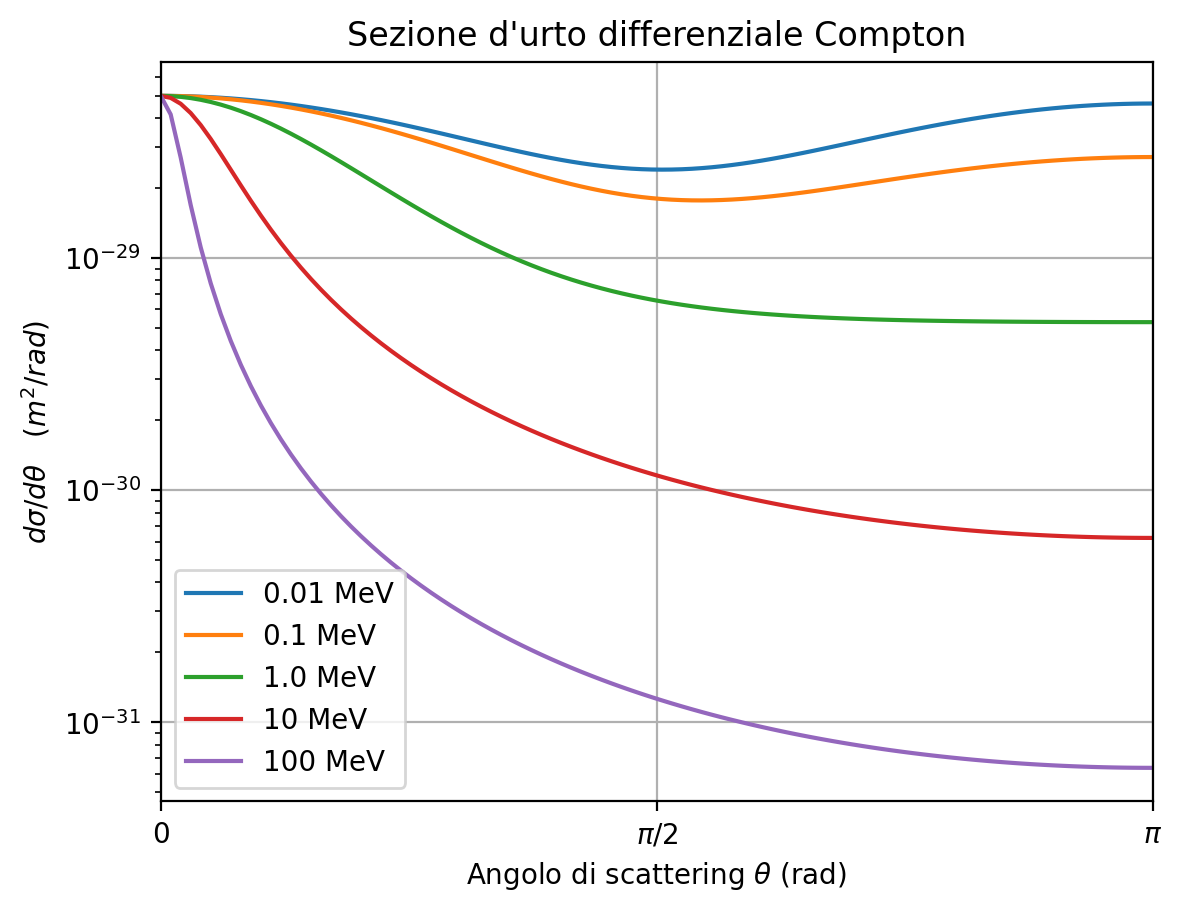

In [15]:

# Grafico di dsigma/dtheta vs. theta per un'energia fissata
omega_fixed = [0.01,0.1,1.0,10,100]  # Energia del fotone in MeV
theta_vals = np.linspace(0, np.pi, 100)

print([x for x in np.linspace(0, np.pi, 4)])
print([x*radians for x in np.linspace(0, np.pi, 4)])

for omega in omega_fixed:
    dsigma_dtheta_vals = [dsigma_dtheta(t, omega) for t in theta_vals]
    plt.plot([x*radians for x in theta_vals], dsigma_dtheta_vals, label=f"{omega} MeV", xunits=radians)
plt.xlabel(r'Angolo di scattering $\theta$ (rad)')
plt.ylabel(r"$d\sigma/d\theta \quad (m^2/rad)$")
plt.yscale("log")
plt.title(r"Sezione d'urto differenziale Compton")
plt.grid(True)
plt.legend()
plt.xlim(0,np.pi)
# plt.xticks([0, np.pi/3, np.pi/2, (2*np.pi)/3, np.pi], labels=["0", "$\pi/3$", "$\pi/2$", "$2\pi/3$", "$\pi$"])
plt.show()

## Sezione d'urto totale

In [7]:
# Calcolo della sezione d'urto totale
def total_cross_section(omega):
    """
    Calcola la sezione d'urto totale tramite integrazione numerica.
    """
    result, abs_error = quad(dsigma_dtheta_integranda, 0, np.pi, args=(omega,))
    return result, abs_error

omega = 1  # 1MeV
sigma, err = total_cross_section(omega)
sigma, err

(2.112078833339675e-29, 2.2473225238061793e-34)

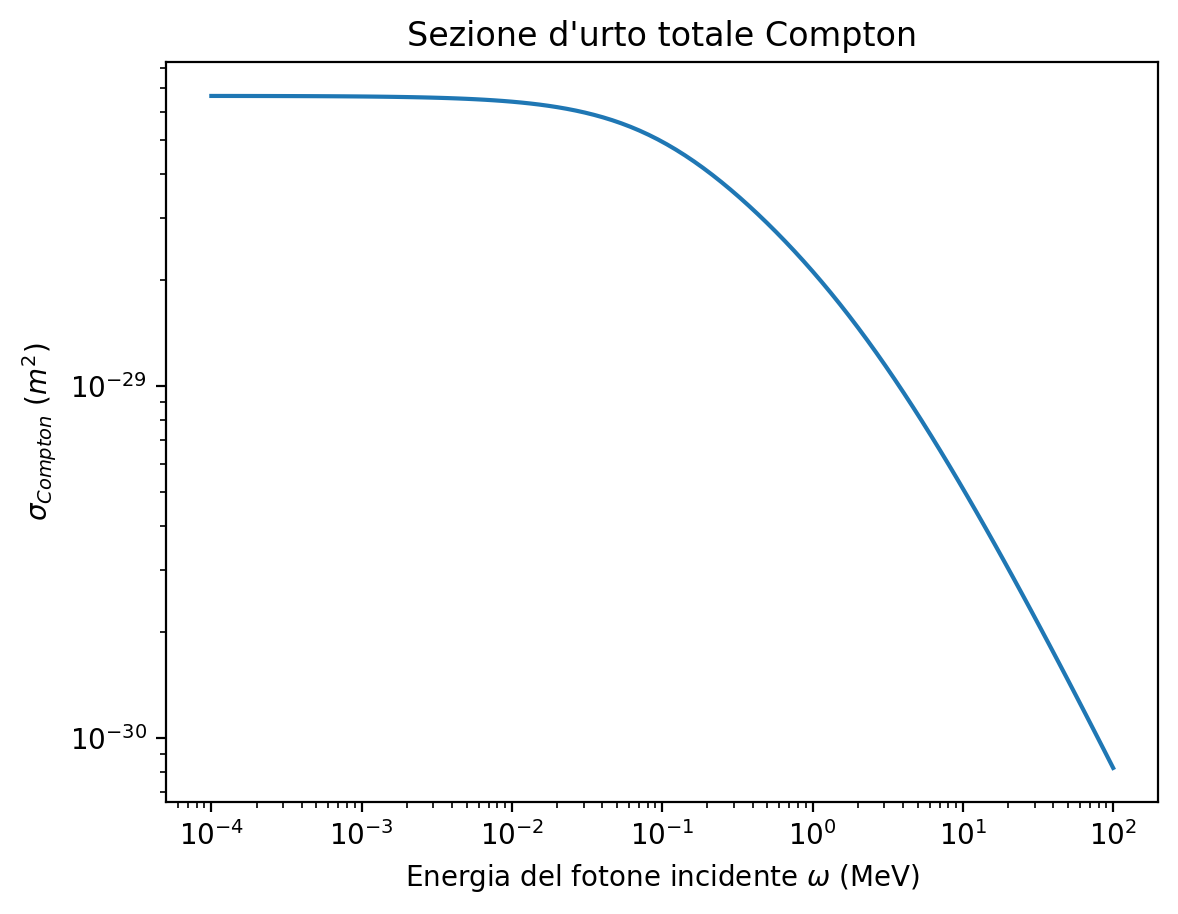

In [31]:
# Grafico della sezione d'urto totale vs. energia del fotone
omega_vals = np.logspace(-4, 2, 100)  # Energias da 0.01 a 100 MeV
integration_vals = [total_cross_section(o)for o in omega_vals]
sigma_vals = [x[0] for x in integration_vals]
error_vals = [x[1] for x in integration_vals]

plt.plot(omega_vals, sigma_vals)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Energia del fotone incidente $\omega$ (MeV)')
plt.ylabel(r'$\sigma_{Compton}$ ($m^2$)')
plt.title('Sezione d\'urto totale Compton')
plt.show()

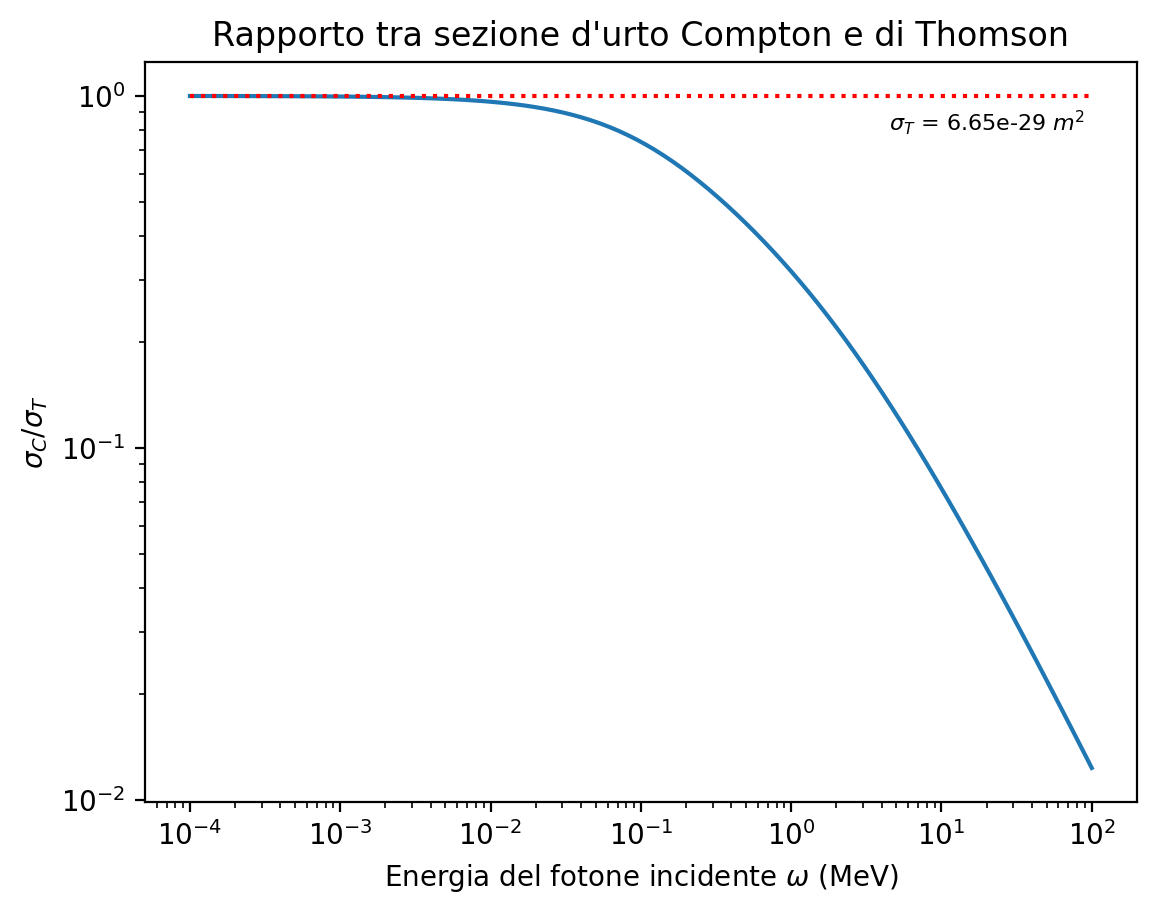

In [32]:
# Grafico della sezione d'urto totale vs. energia del fotone
omega_vals = np.logspace(-4, 2, 100)  # Energias da 0.01 a 100 MeV
integration_vals = [total_cross_section(o)for o in omega_vals]
sigma_vals = [x[0] / sigma_t for x in integration_vals]
error_vals = [x[1] for x in integration_vals]

plt.plot(omega_vals, sigma_vals)
plt.hlines(1, min(omega_vals), max(omega_vals), linestyles="dotted", colors="red")
plt.text(4.5, 0.8, "$\sigma_T$ = 6.65e-29 $m^2$", fontdict={'size': 8})
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Energia del fotone incidente $\omega$ (MeV)')
plt.ylabel(r'$\sigma_C/\sigma_T$')
plt.title('Rapporto tra sezione d\'urto Compton e di Thomson')
plt.show()